# LETF Pitch EDA: does leveraged-ETF rebalancing push the close?

**The mechanism.** A daily leveraged ETF with leverage $L$ and net assets $A$ must hold exposure $L\cdot A$. If the
underlying returns $r$ on the day, NAV becomes $A(1+Lr)$ while the exposure it holds has become $L A (1+r)$. To get
back to $L$ times the new NAV it must trade

$$
\Delta = L A (1+Lr) - L A (1+r) = A \cdot L(L-1) \cdot r
$$

dollars of the underlying at the close. $L(L-1)$ is positive for **every** leveraged or inverse fund (2× long: 2,
1× inverse: 2, 2× inverse: 6), so all of them **buy after up days and sell after down days**, and the size is a
formula: known AUM × known leverage × the day's return. The funds hold swaps; the swap dealers hedge, mostly into the
close.

**Why now.** Single-stock leveraged ETFs only exist in the US since mid-2022 (TSLL, Aug 2022). By 2025–26 there are
hundreds, and in some names (MSTR, TSLA, NVDA, the meme / quantum / crypto-miner names) their combined "gamma"
$\Gamma = \sum_j A_j L_j(L_j-1)$ is a meaningful fraction of daily volume. Earlier work (Cheng & Madhavan 2009;
Baltussen, Da, Lammers & Martens 2021, *JFE*, "Hedging demand and market intraday momentum") studied index
products. The single-stock version is new, and **its size varies a lot across stocks and over time**, which is
what identifies it here.

**The trade (the question from the chat).** The flow lands at the close; you cannot trade *at* the close and beat
it. But the signal is known before: at 15:30 you know AUM (yesterday), leverage, and the return so far. Buy (sell)
at 15:30, exit with a market-on-close order (fills at the official close; NYSE/Nasdaq MOC cutoff 15:50).

**Questions.**
1. **How big is the flow?** Predicted rebalance as % of average daily volume, by stock and over time.
2. **Mechanism.** On days with a big predicted flow, is closing volume abnormally high?
3. **Where does the impact land?** Return in each 5-minute bucket regressed on the predicted flow known at its
   start. Rebalancing should show up near the close; generic intraday momentum would show up everywhere.
4. **The last 30 minutes.** Does predicted flow at 15:30 forecast the 15:30 → close return, beyond plain intraday
   momentum (same return so far, low LETF gamma)?
5. **Reversal.** Is the push temporary (reverses overnight / next day)?
6. **Tradable?** Rule fixed in-sample (2022-07 → 2024-12), tested out-of-sample (2025 → now), after cost.

**Data** (all free)
| file | source | what |
|---|---|---|
| `universe.csv` | SEC series/class list | every single-stock leveraged / inverse ETF: leverage, underlying (`collect_universe.py`) |
| `nport.csv` | SEC Form N-PORT-P | quarter-end net assets + monthly flows and returns per fund (`collect_nport.py`) |
| `daily.csv` | Yahoo | daily OHLCV for the ETFs and the stocks; official closes (`collect_daily.py`) |
| `intraday/*.csv` | Twelve Data | 5-minute regular-session bars for the underlyings + SPY (`collect_intraday.py`) |

**Realism rules**
* **AUM is stale on purpose.** Issuers publish shares outstanding daily, but the free history is N-PORT month-end
  net assets. AUM on day $t$ = shares at the last month-end before $t$ × the ETF's close on $t-1$. That is coarser than
  what a trader sees, so it can only weaken the signal.
* **Signal timing.** Predicted flow at time $\tau$ uses the return from the previous close to $\tau$ only.
  The 15:30 price is the close of the 15:25–15:30 bar.
* **Exit price** is the official close (closing-auction print) from `daily.csv`, which is what MOC fills at,
  not the last 5-minute bar.
* **Half days** (13:00 close) are dropped: the rebalance happens at 13:00 there.

## 1. Data

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("data")
SPLIT = pd.Timestamp("2025-01-01")      # in-sample 2022-07 .. 2024-12, out-of-sample 2025 ..
START = pd.Timestamp("2022-07-01")

u = pd.read_csv(DATA / "universe.csv")
npt = pd.read_csv(DATA / "nport.csv", parse_dates=["rep_date"])
dly = pd.read_csv(DATA / "daily.csv", parse_dates=["date"])
close = dly.pivot(index="date", columns="ticker", values="close")
adj = dly.pivot(index="date", columns="ticker", values="adj_close")
opn = dly.pivot(index="date", columns="ticker", values="open")
vol = dly.pivot(index="date", columns="ticker", values="volume")
cal = close.index[close.index >= "2021-06-01"]
u = u[u.etf.isin(close.columns) & u.under.isin(close.columns)].copy()
# a few tickers were reserved by two trusts (e.g. AVGU: GraniteShares and T-REX); the one that files N-PORT trades it
u["reports"] = u.series_id.map(npt.groupby("series_id").size()).fillna(0)
u = u.sort_values("reports", ascending=False).drop_duplicates("etf").sort_values(["under", "lev"])
u["gam"] = u.lev * (u.lev - 1)          # L(L-1): $ traded per $ of AUM per unit of underlying return
print(f"{len(u)} ETFs with prices on {u.under.nunique()} stocks; N-PORT: {len(npt)} reports, "
      f"{npt.series_id.nunique()} series, {npt.rep_date.min().date()} .. {npt.rep_date.max().date()}")
print(u.groupby("lev").size().rename("funds").to_frame().assign(gamma=lambda d: d.index * (d.index - 1)).T.to_string())

245 ETFs with prices on 141 stocks; N-PORT: 1398 reports, 275 series, 2022-09-30 .. 2026-07-31
lev    -2.00  -1.50  -1.00    1.25   2.00
funds   20.0   1.00   23.0  1.0000  200.0
gamma    6.0   3.75    2.0  0.3125    2.0


**What this does.** Turns each quarterly N-PORT report into three month-end net-asset values. The report gives
net assets at the end of month 3 directly; month 2 is month 3 with month 3's flows removed and its return undone,
$A_{2} = (A_{3} - \text{sales}_3 + \text{redemptions}_3)/(1+r_3)$, and the same again for month 1. Month-end shares =
net assets / the ETF's close that day. Shares are carried forward (from the next trading day) for at most 70 trading
days; a fund before its first report counts as zero.

In [2]:
sid2etf = u.set_index("series_id").etf
flow_cols = [c for c in npt.columns if c.startswith(("sales", "redemption", "reinvest"))]
npt[flow_cols] = npt[flow_cols].fillna(0)
rows = []
for r in npt[npt.series_id.isin(sid2etf.index)].itertuples(index=False):
    na, m = r.net_assets, r.rep_date + pd.offsets.MonthEnd(0)
    if not na > 0:
        continue
    rows.append((r.series_id, m, na))
    for k in (3, 2):
        ret = getattr(r, f"rtn{k}")
        if pd.isna(ret):
            break
        prev = (na - getattr(r, f"sales{k}") + getattr(r, f"redemption{k}") - getattr(r, f"reinvest{k}")) / (1 + ret / 100)
        if not prev > 0.01 * na:     # fund launched during this month
            break
        na, m = prev, m - pd.offsets.MonthEnd(1)
        rows.append((r.series_id, m, na))
mna = pd.DataFrame(rows, columns=["series_id", "month", "na"]).drop_duplicates(["series_id", "month"])
mna["etf"] = mna.series_id.map(sid2etf)

shares = pd.DataFrame(np.nan, index=cal, columns=sorted(u.etf))
for r in mna.itertuples(index=False):
    px = close[r.etf].loc[:r.month].dropna()
    if len(px) == 0 or (r.month - px.index[-1]).days > 7:
        continue
    i = cal.searchsorted(px.index[-1], side="right")       # known from the next trading day
    if i < len(cal):
        shares.iloc[i, shares.columns.get_loc(r.etf)] = r.na / px.iloc[-1]
shares = shares.ffill(limit=70)
etf_px = close.reindex(cal)[shares.columns]
aum = (shares * etf_px.shift(1)).where(etf_px.notna()).fillna(0)       # $ AUM known at the start of day t

lev_of = u.set_index("etf").lev
gam_of = u.set_index("etf").gam
under_of = u.set_index("etf").under
GAMMA = (aum * gam_of[aum.columns]).T.groupby(under_of[aum.columns]).sum().T     # $ per unit return, per stock
EXPO = (aum * lev_of[aum.columns]).T.groupby(under_of[aum.columns]).sum().T      # net $ exposure (long - short)
stocks = sorted(GAMMA.columns)
dv = (close * vol).reindex(cal)[stocks]
ADV = dv.rolling(20, min_periods=10).mean().shift(1)                              # $ ADV known at the start of t
G = (GAMMA / ADV).replace([np.inf, -np.inf], np.nan)                                # dimensionless
R = adj.reindex(cal)[stocks].pct_change()
FLOW = G * R * 100                                                                 # realised rebalance, % of ADV
print(f"month-end fund sizes: {len(mna)} from {mna.series_id.nunique()} funds; "
      f"total LETF AUM on the last day ${aum.iloc[-1].sum() / 1e9:.1f}bn")

month-end fund sizes: 3684 from 241 funds; total LETF AUM on the last day $18.5bn


## 2. How big is the flow?
**What this does.** Total single-stock LETF AUM over time, and for each stock the gamma ratio
$G = \Gamma / \text{ADV}$: the rebalance as a fraction of a normal day's dollar volume **per unit of return**.
$G = 0.5$ means a 4% day forces trading of 2% of ADV, all aimed at the close. Closing auctions are typically 5–10%
of daily volume in US large caps, so a few % of ADV at the close is large.

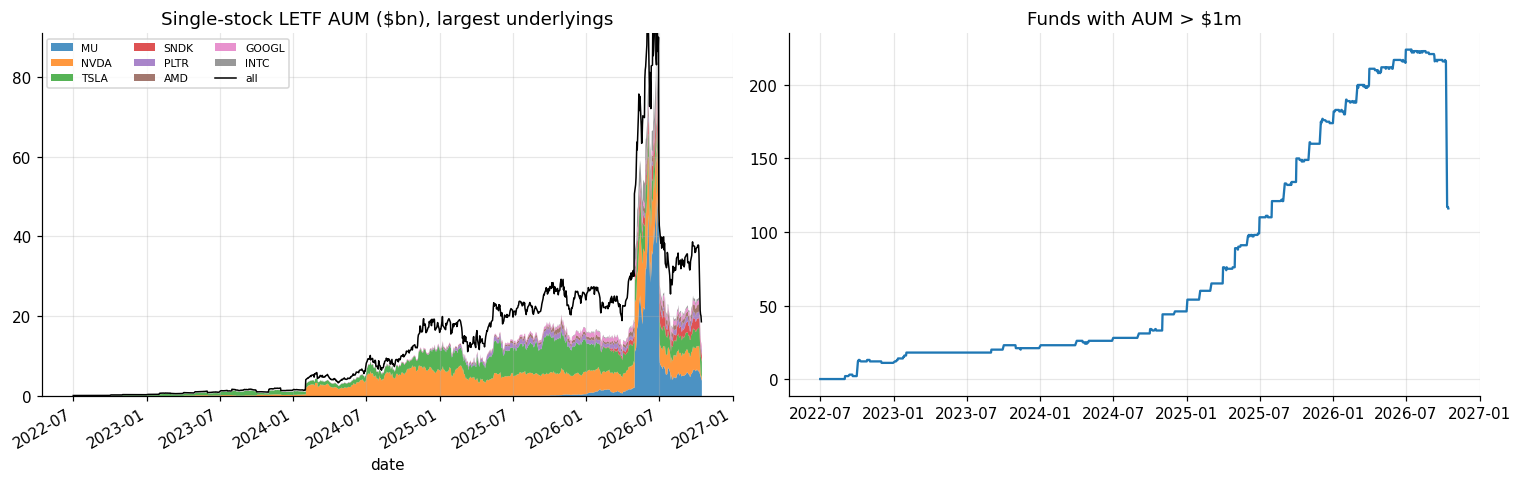

last 90 days, stocks with > $5m of LETF AUM and > $5m ADV, sorted by G:
       AUM $m  gamma $m per 1%    ADV $m     G  net lev expo / ADV  |flow| % ADV, median day  |flow| % ADV, 90th pct day
BMNR   423.19             8.46    822.18  1.04                1.04                      2.96                        8.45
COIN   652.60            13.05   1537.32  0.87                0.87                      2.77                        7.86
MSTR   472.06            14.09   2685.26  0.66                0.17                      1.73                        6.28
TSLA  4114.03            89.36  13750.30  0.66                0.54                      1.03                        2.93
QUBT    22.27             0.45     70.37  0.65                0.65                      1.50                        4.06
ASTS   240.21             4.80    827.58  0.62                0.62                      1.95                        4.89
DJT     11.19             0.22     37.74  0.60                0.60               

In [3]:
s = cal >= START
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
top = aum.T.groupby(under_of[aum.columns]).sum().T.loc[s]
order = top.iloc[-250:].mean().sort_values(ascending=False).index
(top[order[:8]] / 1e9).plot.area(ax=ax[0], lw=0, alpha=0.8)
ax[0].plot(top.index, top.sum(1) / 1e9, c="k", lw=1, label="all")
ax[0].set_title("Single-stock LETF AUM ($bn), largest underlyings"); ax[0].legend(fontsize=7, ncol=3)
nf = (aum.loc[s] > 1e6).sum(1)
ax[1].plot(nf.index, nf); ax[1].set_title("Funds with AUM > $1m")
plt.tight_layout(); plt.show()

last = cal[cal >= cal[-1] - pd.Timedelta(days=90)]
tab = pd.DataFrame({"AUM $m": top.loc[last].mean() / 1e6, "gamma $m per 1%": GAMMA.loc[last].mean() / 1e6 / 100,
                    "ADV $m": ADV.loc[last].mean() / 1e6, "G": G.loc[last].mean(),
                    "net lev expo / ADV": (EXPO / ADV).loc[last].mean(),
                    "|flow| % ADV, median day": FLOW.loc[last].abs().median(),
                    "|flow| % ADV, 90th pct day": FLOW.loc[last].abs().quantile(0.9)})
tab = tab[(tab["AUM $m"] > 5) & (tab["ADV $m"] > 5)].sort_values("G", ascending=False)
print("last 90 days, stocks with > $5m of LETF AUM and > $5m ADV, sorted by G:")
print(tab.head(30).round(2).to_string())
print(f"\n{(tab.G > 0.1).sum()} stocks with G > 0.1, {(tab.G > 0.5).sum()} with G > 0.5")

**Interpretation.**
- **The flow is real money.** About $18.5bn sits in single-stock leveraged / inverse ETFs (the mid-2026 N-PORT figure
  carried forward), in about 245 funds on 141 stocks. Almost all of it has arrived since 2024.
- **In a handful of names it is large relative to volume.** 58 stocks have $G > 0.1$ and 7 have $G > 0.5$. In the last
  90 days, BMNR (1.04), COIN (0.87), MSTR (0.66), TSLA (0.66) and the quantum / space names lead. On a median day
  the forced trade is 1–3% of ADV; on a 90th-percentile day it is 3–8%.
- **MSTR shows why gamma, not net exposure, is the right measure.** Its net leveraged exposure is only 0.17× ADV,
  because the inverse funds offset the long ones, but all of them trade the *same* direction at the close
  ($L(L-1) > 0$). That gives $G = 0.66$.

**What this does.** $G$ over time for the stocks with intraday data, the cross-section the rest of the notebook
uses. The time variation matters: in 2022–23 most of these names had almost no LETF AUM, so they serve as their own
control group.

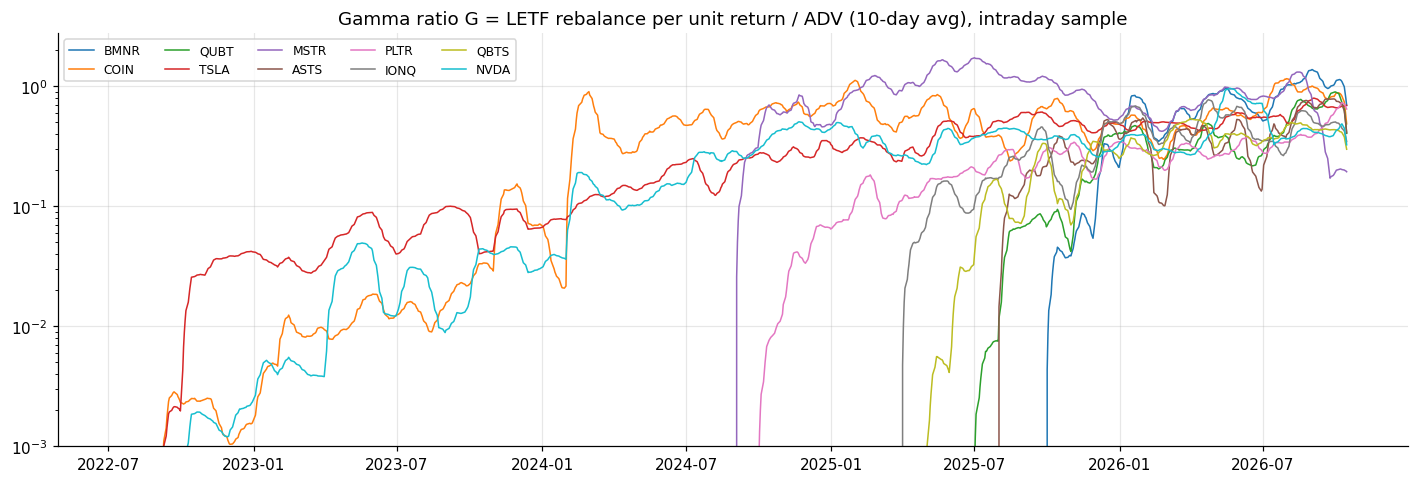

intraday sample: 30 stocks: AAOI AAPL AMD AMZN ASTS AVGO BMNR COIN CRCL GOOGL HIMS HOOD IONQ IREN META MSFT MSTR MU NOW NVDA OKLO PLTR QBTS QUBT RGTI RKLB SMCI SMR TSLA TSM


In [4]:
SYMS = sorted(p.stem.replace("-", ".") for p in (DATA / "intraday").glob("*.csv") if p.stem != "SPY")
SYMS = [x for x in SYMS if x in G.columns]
fig, ax = plt.subplots(figsize=(13, 4.5))
for x in G[SYMS].loc[s].iloc[-60:].mean().sort_values(ascending=False).index[:10]:
    ax.plot(G.index[s], G[x].loc[s].rolling(10).mean(), lw=1, label=x)
ax.set_yscale("log"); ax.set_ylim(1e-3, None); ax.legend(ncol=5, fontsize=8)
ax.set_title("Gamma ratio G = LETF rebalance per unit return / ADV (10-day avg), intraday sample")
plt.tight_layout(); plt.show()
print("intraday sample:", len(SYMS), "stocks:", " ".join(SYMS))

## 3. Intraday panel
**What this does.** Loads the 5-minute bars, keeps full sessions (78 bars, so half days drop out), and expresses
every price as a log return from the previous close (dividend-adjusted, so an ex-date gap is not a return).
`L[:, k]` = return from the previous close to the end of bar k; `LC` = to the official close. The gap between the
15:55 bar close and the official close is the closing auction.

In [5]:
BARS = pd.date_range("2000-01-01 09:30", "2000-01-01 15:55", freq="5min").strftime("%H:%M")
K30 = list(BARS).index("15:25")          # bar ending 15:30: LL[:, K30] is the 15:30 price

def load(sym):
    x = pd.read_csv(DATA / "intraday" / f"{sym.replace('.', '-')}.csv", parse_dates=["datetime"])
    x["date"] = x.datetime.dt.normalize(); x["hm"] = x.datetime.dt.strftime("%H:%M")
    c = x.pivot_table(index="date", columns="hm", values="close").reindex(columns=BARS)
    v = x.pivot_table(index="date", columns="hm", values="volume").reindex(columns=BARS)
    ok = c.notna().sum(1) >= 76
    ok &= c["15:55"].notna()
    return c[ok].ffill(axis=1), v[ok]

def panel(sym):
    c, v = load(sym)
    d = c.index.intersection(cal)
    C = close[sym].reindex(d); pc = C * adj[sym].shift(1).reindex(d) / adj[sym].reindex(d)   # prev close, today's terms
    L = np.log(c.loc[d].values / pc.values[:, None])
    LC = np.log(C.values / pc.values)
    nxt_open = (opn[sym] * adj[sym] / close[sym]).shift(-1).reindex(d)                      # adj. next open
    df = pd.DataFrame({"sym": sym, "date": d, "LC": LC,
                       "ron": np.log(nxt_open.values / adj[sym].reindex(d).values),
                       "rnext": np.log(adj[sym].shift(-1) / adj[sym]).reindex(d).values,
                       "vol_intra": v.loc[d].sum(1).values, "vol_day": vol[sym].reindex(d).values,
                       "vol_last30": v.loc[d].iloc[:, K30 + 1:].sum(1).values,
                       "G": G[sym].reindex(d).values if sym in G else 0.0,
                       "sig": np.log(adj[sym]).diff().rolling(20).std().shift(1).reindex(d).values})
    return df, L

parts, Ls = [], []
for sym in SYMS + ["SPY"]:
    df, L = panel(sym); parts.append(df); Ls.append(L)
P = pd.concat(parts, ignore_index=True); LL = np.vstack(Ls)
P = P[P.date >= START]; LL = LL[P.index]; P = P.reset_index(drop=True)
bad = np.abs(LL[:, -1] - P.LC.values) > 0.05       # 15:55 bar vs official close > 5%: split/vendor mismatch
P, LL = P[~bad].reset_index(drop=True), LL[~bad]
print(f"{len(P):,} stock-days, {P.sym.nunique()} symbols, {P.date.min().date()} .. {P.date.max().date()}; dropped {bad.sum()} mismatched days")
print("median |15:55 bar close − official close|, bp:", round(np.nanmedian(np.abs(LL[:, -1] - P.LC.values)) * 1e4, 2))

30,167 stock-days, 31 symbols, 2022-07-01 .. 2026-10-14; dropped 1 mismatched days
median |15:55 bar close − official close|, bp: 1.91


**What this does.** Splits off SPY (used as the market control: the same bucket's SPY return) and builds, for every
bucket k, the bucket return and the signal known at its start. Bucket 78 is the auction: official close vs the last
5-minute bar.

In [6]:
isspy = (P.sym == "SPY").values
SPYL = pd.DataFrame(LL[isspy], index=P.date[isspy]); SPYC = pd.Series(P.LC.values[isspy], index=P.date[isspy])
SPYON = pd.Series(P.ron.values[isspy], index=P.date[isspy])      # SPY close -> next open
P, LL = P[~isspy].reset_index(drop=True), LL[~isspy]
LLc = np.column_stack([LL, P.LC.values])                       # 79 points: end of each bar, then the official close
SPc = np.column_stack([SPYL.reindex(P.date).values, SPYC.reindex(P.date).values])
RET = np.diff(LLc, axis=1) * 1e4                                # bp; column j = return from point j to j+1
SRET = np.diff(SPc, axis=1) * 1e4
Gv = np.nan_to_num(P.G.values)
def flow_at(j):          # predicted rebalance (% ADV) from the return to point j
    return Gv * (np.exp(LLc[:, j]) - 1) * 100
LABELS = list(BARS[1:]) + ["auction"]
print("G in the intraday panel: share of stock-days with G > 0.1:", f"{(Gv > 0.1).mean():.0%}", "| > 0.5:", f"{(Gv > 0.5).mean():.0%}")

G in the intraday panel: share of stock-days with G > 0.1: 30% | > 0.5: 6%


## 4. Mechanism: do big predicted flows come with heavy closing volume?
**What this does.** Volume in the last 30 minutes + the auction, as a share of the day's volume, against the
realised flow $|G\,r|$ (% of ADV). Plain big-move days also trade more, so the regression controls for $|r|$.
If LETF rebalancing is real, $|G r|$ should add closing volume on top of $|r|$.

In [7]:
P["close_share"] = (P.vol_last30 + (P.vol_day - P.vol_intra).clip(lower=0)) / P.vol_day
P["absr"] = np.abs(np.exp(P.LC) - 1) * 100
P["absflow"] = Gv * P.absr
d = P.replace([np.inf, -np.inf], np.nan).dropna(subset=["close_share", "absr", "absflow"])
d = d[(d.close_share > 0) & (d.close_share < 1)]
X = sm.add_constant(d[["absr", "absflow"]])
f = sm.OLS(d.close_share * 100, X).fit(cov_type="cluster", cov_kwds={"groups": d.date.factorize()[0]})
print(f.summary().tables[1])
d["fb"] = pd.qcut(d.absflow.rank(method="first"), 10, labels=False) + 1
print("\nclose share of volume (%) by |predicted flow| decile:")
print(d.groupby("fb").agg(absflow=("absflow", "mean"), absr=("absr", "mean"), close_share=("close_share", lambda x: x.mean() * 100)).round(2).to_string())
print(f"\nintraday bars capture a median {np.nanmedian(P.vol_intra / P.vol_day):.0%} of daily volume "
      "(the rest is auctions + any off-feed volume, so treat the auction share as approximate)")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         25.0094      0.540     46.288      0.000      23.950      26.068
absr          -0.3568      0.167     -2.136      0.033      -0.684      -0.029
absflow        0.1705      0.225      0.756      0.449      -0.271       0.612

close share of volume (%) by |predicted flow| decile:
    absflow  absr  close_share
fb                            
1      0.00  4.27        24.06
2      0.00  4.03        21.92
3      0.00  3.11        25.09
4      0.00  5.25        17.50
5      0.00  1.87        25.17
6      0.02  1.27        28.96
7      0.08  1.71        26.76
8      0.26  2.47        23.83
9      0.79  3.57        22.39
10     3.16  6.75        22.91

intraday bars capture a median 91% of daily volume (the rest is auctions + any off-feed volume, so treat the auction share as approximate)


**Interpretation.**
- **No detectable extra closing volume.** Once the day's move $|r|$ is controlled for, predicted flow adds
  +0.17pp of closing share per 1% of ADV (t = 0.8). An early run on 6 stocks showed t = 11; it did not survive the
  full 30-stock panel. The measure is noisy, though: the 5-minute feed carries a median 91% of reported daily volume,
  so the "auction" share is inferred, and its level swings with the vendor's coverage (decile 4 at 17.5% vs 29% in
  decile 6, with no pattern). This test cannot rule the mechanism in or out.

## 5. Where does the impact land? Bucket-by-bucket regressions
**What this does.** For every 5-minute bucket, regress its return (bp) on what is known at its start:

$$ r_{k} = a + b\, r_{0\to k} + c\, F_{k} + d\, r^{SPY}_{k} + \varepsilon $$

$r_{0\to k}$ = return from the previous close (%), plain intraday momentum / reversal. $F_k = G \cdot r_{0\to k}$ =
predicted LETF rebalance (% of ADV) if the day ended now. $r^{SPY}_k$ = SPY's same-bucket return (market control).
Standard errors clustered by date. **$c$ is the LETF effect**: extra continuation per 1% of ADV of predicted flow, beyond
what the same return does in a stock with no LETFs. Rebalancing predicts $c > 0$ concentrated in the last buckets.

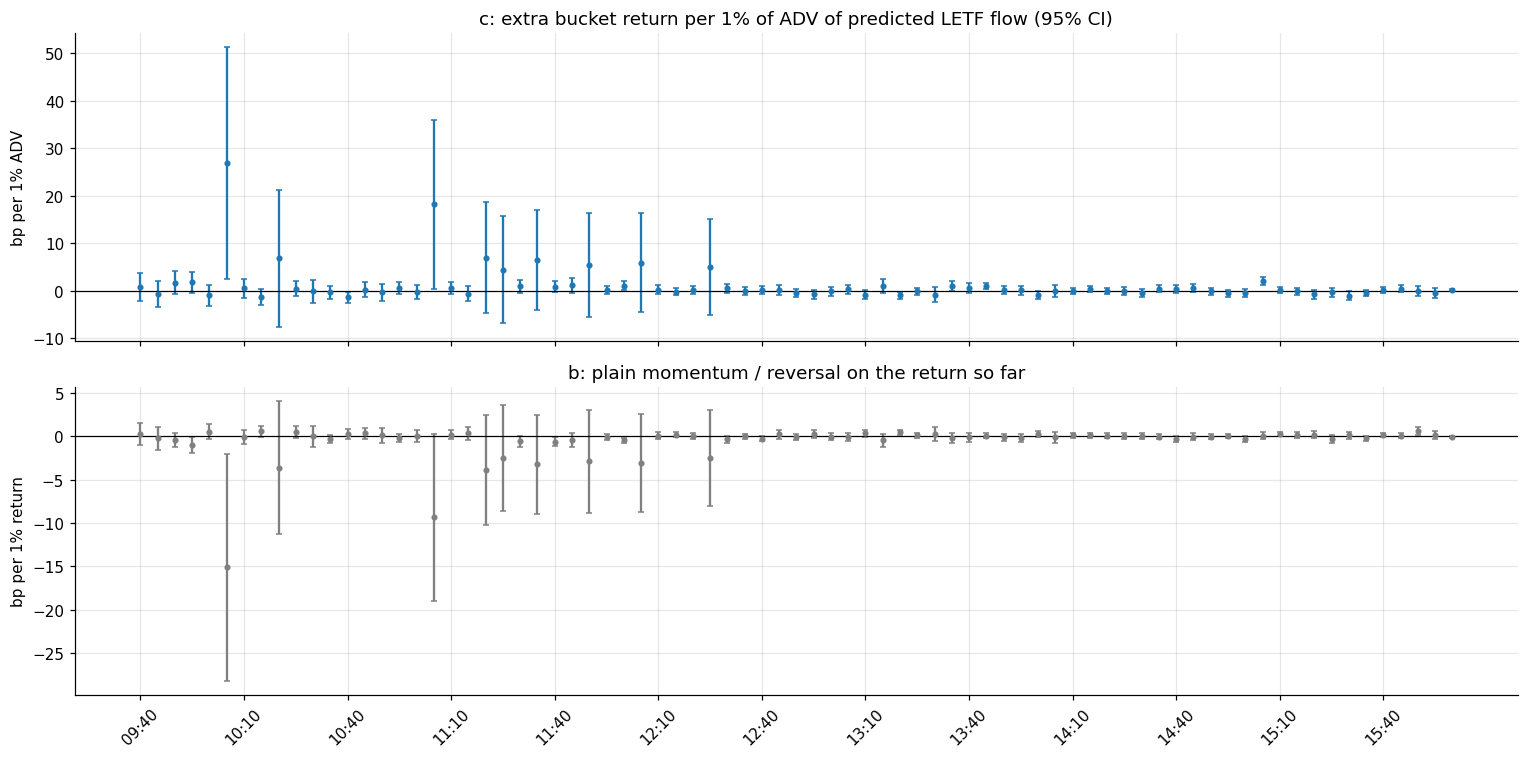

 bucket  b_mom  se_mom  c_flow  se_flow     n  t_flow
  15:05  0.100   0.201   1.983    0.430 29087   4.612
  15:10  0.282   0.143   0.160    0.361 29087   0.442
  15:15  0.162   0.160  -0.054    0.371 29087  -0.145
  15:20  0.205   0.220  -0.693    0.473 29087  -1.465
  15:25 -0.299   0.216  -0.337    0.487 29087  -0.692
  15:30  0.125   0.190  -0.992    0.442 29087  -2.246
  15:35 -0.190   0.142  -0.476    0.355 29087  -1.341
  15:40  0.126   0.112   0.209    0.328 29087   0.636
  15:45  0.056   0.145   0.457    0.367 29087   1.244
  15:50  0.605   0.250  -0.052    0.562 29087  -0.093
  15:55  0.178   0.240  -0.527    0.549 29087  -0.959
auction -0.054   0.063   0.137    0.120 29087   1.135


In [8]:
def bucket_reg(j, mask=None):
    m = np.ones(len(P), bool) if mask is None else mask
    y = RET[:, j]; X = np.column_stack([np.ones(len(P)), LLc[:, j] * 100, flow_at(j), SRET[:, j]])
    ok = m & np.isfinite(y) & np.isfinite(X).all(1)
    f = sm.OLS(y[ok], X[ok]).fit(cov_type="cluster", cov_kwds={"groups": P.date.values[ok].astype("int64")})
    return f.params, f.bse, ok.sum()

res = []
for j in range(1, RET.shape[1]):              # skip the opening bar
    b, se, n = bucket_reg(j)
    res.append({"bucket": LABELS[j], "b_mom": b[1], "se_mom": se[1], "c_flow": b[2], "se_flow": se[2], "n": n})
res = pd.DataFrame(res)
fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
x = np.arange(len(res))
ax[0].errorbar(x, res.c_flow, yerr=1.96 * res.se_flow, fmt="o", ms=3, capsize=2)
ax[0].axhline(0, c="k", lw=0.8); ax[0].set_ylabel("bp per 1% ADV")
ax[0].set_title("c: extra bucket return per 1% of ADV of predicted LETF flow (95% CI)")
ax[1].errorbar(x, res.b_mom, yerr=1.96 * res.se_mom, fmt="o", ms=3, capsize=2, c="gray")
ax[1].axhline(0, c="k", lw=0.8); ax[1].set_ylabel("bp per 1% return")
ax[1].set_title("b: plain momentum / reversal on the return so far")
ax[1].set_xticks(x[::6]); ax[1].set_xticklabels(res.bucket[::6], rotation=45)
plt.tight_layout(); plt.show()
print(res.assign(t_flow=res.c_flow / res.se_flow).tail(12).round(3).to_string(index=False))

**Interpretation.**
- **No push into the close.** In the last half hour, $c$ is not positive in any bucket. The 15:30 bucket is
  *negative* (−0.99bp per 1% ADV, t = −2.2), and the auction itself is +0.14 (t = 1.1).
- **One odd blip at 15:05** (+1.98, t = 4.6). It survives a Bonferroni correction across 77 buckets (p ≈ 3×10⁻⁴), so it
  is probably not noise. One reading: some swap dealers start hedging at 15:00, not into the close. It is worth a
  follow-up, but a single 5-minute bucket is too small to trade.
- **Plain intraday momentum ($b$) is weak too**, with mostly |t| < 2. The exception is the 15:50 bucket (+0.6, t = 2.4),
  when MOC imbalances are first published.

## 6. The last 30 minutes
**What this does.** The tradable window: signal $F_{15:30} = G \cdot r_{\text{prev close} \to 15:30}$, outcome the return
from 15:30 to the official close. First a regression with the same controls as §5, then sorts:

* **Decile sort on $F$** (pooled over all stock-days): mean signed 15:30→close return.
* **Double sort**: return-so-far bucket × G tercile. If it is LETF flow rather than intraday momentum, the
  continuation should grow with G *within* the same return-so-far bucket.

all            n= 29087  b(rs)=+1.68 (t +1.9)  c(F)=-3.16 (t -1.7)
in-sample      n= 15997  b(rs)=+1.05 (t +2.0)  c(F)=-3.05 (t -1.4)
out-of-sample  n= 13090  b(rs)=+2.21 (t +1.7)  c(F)=-3.99 (t -1.6)

15:30 -> close return (bp) by decile of predicted flow F:
       F    rs   r30     n     t
Fd                              
1  -1.83 -4.67  0.01  2909  0.00
2  -0.17 -2.00  1.97  2909  1.52
3  -0.01 -0.57  2.89  2908  2.12
4   0.00  0.54 -0.15  2909 -0.08
5   0.00  0.44  1.72  2909  0.97
6   0.00  0.23  8.15  2908  3.99
7   0.00  0.47  6.87  2909  2.84
8   0.01  0.88  1.26  2908  1.49
9   0.15  2.08  0.98  2909  0.80
10  2.01  5.43  1.88  2909  1.13

mean 15:30 -> close return (bp): return-so-far bucket (%) x G tercile
Gt              low G  mid G  high G
rsb                                 
(-100.0, -4.0]    7.8    2.3     2.0
(-4.0, -2.0]      3.5    3.5     1.2
(-2.0, -0.5]      1.3    3.0     0.3
(-0.5, 0.5]       2.5    0.9     2.2
(0.5, 2.0]        0.3    0.7     0.8
(2.0, 4.0]    

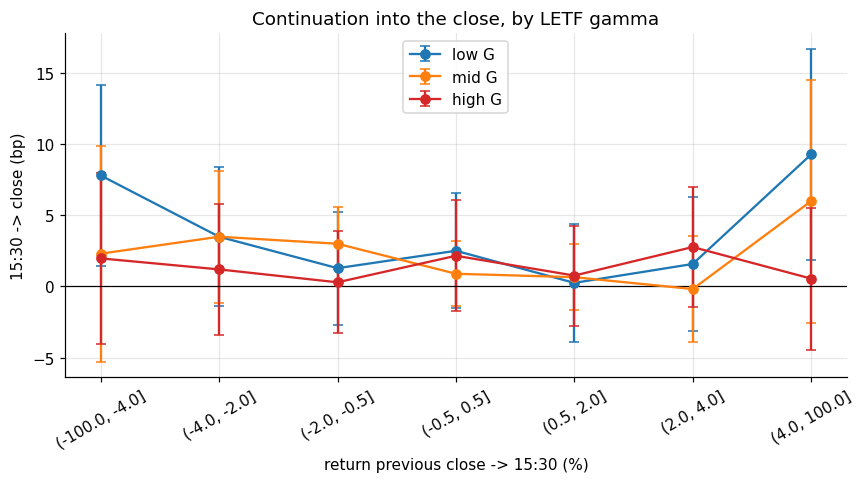

In [9]:
P["r30"] = (LLc[:, -1] - LLc[:, K30]) * 1e4            # 15:30 -> official close, bp
P["spy30"] = (SPc[:, -1] - SPc[:, K30]) * 1e4
P["rs"] = (np.exp(LLc[:, K30]) - 1) * 100              # return so far at 15:30, %
P["F"] = Gv * P.rs                                         # predicted flow at 15:30, % ADV
P["is"] = P.date < SPLIT
d = P.dropna(subset=["r30", "rs", "F", "spy30"])
for name, m in [("all", d.index == d.index), ("in-sample", d["is"]), ("out-of-sample", ~d["is"])]:
    dd = d[m]
    f = sm.OLS(dd.r30, sm.add_constant(dd[["rs", "F", "spy30"]])).fit(cov_type="cluster", cov_kwds={"groups": dd.date.factorize()[0]})
    print(f"{name:14s} n={len(dd):6d}  b(rs)={f.params.rs:+.2f} (t {f.tvalues.rs:+.1f})  c(F)={f.params.F:+.2f} (t {f.tvalues.F:+.1f})")

d["Fd"] = pd.qcut(d.F.rank(method="first"), 10, labels=False) + 1
g = d.groupby("Fd").agg(F=("F", "mean"), rs=("rs", "mean"), r30=("r30", "mean"), n=("r30", "size"))
g["t"] = d.groupby("Fd").r30.apply(lambda x: x.mean() / x.std() * np.sqrt(len(x)))
print("\n15:30 -> close return (bp) by decile of predicted flow F:")
print(g.round(2).to_string())

d["rsb"] = pd.cut(d.rs, [-100, -4, -2, -0.5, 0.5, 2, 4, 100])
d["Gt"] = pd.qcut(d.G.rank(method="first"), 3, labels=["low G", "mid G", "high G"])
print("\nmean 15:30 -> close return (bp): return-so-far bucket (%) x G tercile")
print(d.pivot_table(index="rsb", columns="Gt", values="r30", aggfunc="mean", observed=True).round(1).to_string())
print(d.pivot_table(index="rsb", columns="Gt", values="r30", aggfunc="size", observed=True).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
for gt, c in zip(["low G", "mid G", "high G"], ["C0", "C1", "C3"]):
    x = d[d.Gt == gt].groupby("rsb", observed=True)
    ax.errorbar(np.arange(x.ngroups), x.r30.mean(), yerr=1.96 * x.r30.sem(), label=gt, c=c, capsize=3, marker="o")
ax.set_xticks(np.arange(7)); ax.set_xticklabels([str(i) for i in d.rsb.cat.categories], rotation=30)
ax.axhline(0, c="k", lw=0.8); ax.set_xlabel("return previous close -> 15:30 (%)"); ax.set_ylabel("15:30 -> close (bp)")
ax.legend(); ax.set_title("Continuation into the close, by LETF gamma"); plt.tight_layout(); plt.show()

**Interpretation.**
- **The thesis fails here.** Predicted flow at 15:30 *lowers* the 15:30 → close return: $c = -3.2$bp per 1% ADV
  (t = −1.7), with the same sign in-sample (−3.1) and out-of-sample (−4.0). The decile sort has no slope: the two
  extreme deciles earn +0.0 and +1.9bp.
- **The double sort points the wrong way.** On days up more than 4% by 15:30, low-G stocks gain another +9.3bp into
  the close, but high-G stocks gain only +0.6bp. If LETF buying pushed the close, high G would show *more*
  continuation, not less.
- **Possible reasons:** the flow is pre-positioned (market makers and other traders know the formula too),
  dealers hedge earlier (see the 15:05 blip), or closing liquidity absorbs it. Either way, a trader entering at
  15:30 finds nothing left.

## 7. Is the push temporary?
**What this does.** If the close is pushed by price-insensitive flow, part of it should come back. Regress the
overnight return (close → next open) and the next day's close-to-close return on the realised flow
$F_{close} = G \cdot r_{\text{day}}$ (the flow actually traded), with the day's own return as a control.

In [10]:
d = P.copy()
d["rday"] = (np.exp(d.LC) - 1) * 100
d["Fc"] = Gv * d.rday
d = d.dropna(subset=["ron", "rnext", "rday", "Fc"])
for y in ["ron", "rnext"]:
    f = sm.OLS(d[y] * 1e4, sm.add_constant(d[["rday", "Fc"]])).fit(cov_type="cluster", cov_kwds={"groups": d.date.factorize()[0]})
    print(f"{y:6s}: b(rday)={f.params.rday:+.2f} bp/% (t {f.tvalues.rday:+.1f}), c(Fc)={f.params.Fc:+.2f} bp per 1% ADV (t {f.tvalues.Fc:+.1f})")
d["Fd"] = pd.qcut(d.Fc.rank(method="first"), 10, labels=False) + 1
print(d.groupby("Fd").agg(Fc=("Fc", "mean"), r_auction=("LC", lambda x: np.nan), ron=("ron", lambda x: x.mean() * 1e4),
                          rnext=("rnext", lambda x: x.mean() * 1e4)).drop(columns="r_auction").round(2).to_string())

ron   : b(rday)=+3.96 bp/% (t +3.4), c(Fc)=-11.27 bp per 1% ADV (t -3.4)
rnext : b(rday)=+3.23 bp/% (t +2.7), c(Fc)=-13.24 bp per 1% ADV (t -2.5)
      Fc    ron  rnext
Fd                    
1  -1.87  22.46  19.18
2  -0.17   4.73  21.32
3  -0.01  13.81  14.08
4   0.00  17.40  25.76
5   0.00  22.29  30.79
6   0.00  32.99  11.56
7   0.00  41.92  29.02
8   0.01   8.55  13.51
9   0.16  17.73   5.99
10  2.05   4.92  -8.89


**Interpretation.**
- **The overnight reversal is the one live result.** After controlling for the day's own return, realised flow
  predicts a lower close → next open return: −11.3bp per 1% ADV (t = −3.4) overnight, and −13.2bp (t = −2.5) on the
  next day close to close. In the top flow decile (+2% ADV), the next day is −8.9bp, against +6 to +31bp for
  the others.
- **This sits awkwardly with §6.** No push into the close is visible, yet part of something reverses overnight. One
  reading: the push is spread through the afternoon, then given back. Another: high-G names are volatile meme
  names that reverse after big days for their own reasons. The next cell tests the second reading.

**Tradable version of the reversal.** The realised flow is only known at 16:00, so use what is known at the MOC
cutoff: $F_{15:50} = G \cdot r_{\text{prev close} \to 15:50}$. Rule: if $|F_{15:50}| \ge k$, take the **opposite**
side with a MOC order (fills at the official close, no spread), exit with a market-on-open order next morning (fills at
the opening auction, no spread). Market-adjusted with SPY's close → open. In-sample picks $k$; out-of-sample reports.

In [11]:
K50 = list(BARS).index("15:45")          # bar ending 15:50
KS = [0.05, 0.1, 0.25, 0.5, 1, 2, 5]     # thresholds, % of ADV
d = P.copy()
d["r50"] = (np.exp(LLc[:, K50]) - 1) * 100               # return previous close -> 15:50, %
d["F50"] = Gv * d.r50
d["ron_adj"] = (d.ron - SPYON.reindex(d.date).values) * 1e4     # SPY-adjusted close -> next open, bp
d["pnl"] = -np.sign(d.F50) * d.ron_adj
d = d.dropna(subset=["pnl", "F50", "sig"])
def rev_stats(dd, k, cost=0.0):
    t = dd[dd.F50.abs() >= k]
    if len(t) < 20:
        return dict(k=k, trades=len(t))
    daily = (t.pnl - cost).groupby(t.date).mean().reindex(dd.date.unique(), fill_value=0)
    cl = sm.OLS(t.pnl - cost, np.ones(len(t))).fit(cov_type="cluster", cov_kwds={"groups": t.date.factorize()[0]})
    return dict(k=k, trades=len(t), bp_per_trade=t.pnl.mean() - cost, t=cl.tvalues.iloc[0], hit=(t.pnl > cost).mean(),
                sharpe=daily.mean() / daily.std() * np.sqrt(252))
for name, m in [("in-sample", d["is"]), ("out-of-sample", ~d["is"])]:
    print(name); print(pd.DataFrame([rev_stats(d[m], k) for k in KS]).round(2).to_string(index=False)); print()
ins = pd.DataFrame([rev_stats(d[d["is"]], k, 2) for k in KS]).dropna()
KR = ins.loc[ins.sharpe.idxmax(), "k"]
print(f"chosen k = {KR}% of ADV")
for c in [0, 2, 5, 10]:
    a, b = rev_stats(d[d["is"]], KR, c), rev_stats(d[~d["is"]], KR, c)
    print(f"cost {c:2d} bp: IS {a['bp_per_trade']:+6.2f} bp/trade Sharpe {a['sharpe']:+5.2f} | "
          f"OOS {b['bp_per_trade']:+6.2f} bp/trade Sharpe {b['sharpe']:+5.2f} t {b['t']:+.1f}")
t = d[d.F50.abs() >= KR]
print("\nby year:"); print(t.groupby(t.date.dt.year).pnl.agg(["mean", "count", lambda x: x.mean() / x.std() * np.sqrt(len(x))]).rename(columns={"<lambda_0>": "t"}).round(2).to_string())
print("\nby side:"); print(t.groupby(np.sign(t.F50)).pnl.agg(["mean", "count"]).rename(index={-1: "flow sells -> buy MOC", 1: "flow buys -> sell MOC"}).round(2).to_string())

# is it LETF flow, or do volatile names just reverse overnight after big days? same return, different G
d["sig_r"] = d.r50 * d.sig * 100
f = sm.OLS(d.ron_adj,
           sm.add_constant(d[["r50", "sig_r", "F50"]])).fit(cov_type="cluster", cov_kwds={"groups": d.date.factorize()[0]})
print(f"\novernight (SPY-adj) on r50, r50 x vol, F50: c(F50) = {f.params.F50:+.2f} bp per 1% ADV (t {f.tvalues.F50:+.1f}), "
      f"b(r50) = {f.params.r50:+.2f} (t {f.tvalues.r50:+.1f}), b(r50 x vol) = {f.params.sig_r:+.2f} (t {f.tvalues.sig_r:+.1f})")

in-sample
   k  trades  bp_per_trade     t  hit  sharpe
0.05    1677        -16.63 -2.59 0.50   -2.11
0.10    1171        -18.56 -2.15 0.52   -1.67
0.25     722        -18.32 -1.52 0.55   -0.81
0.50     474        -12.76 -0.80 0.58    0.00
1.00     297        -14.02 -0.68 0.57   -0.14
2.00     147        -26.23 -0.84 0.55   -0.75
5.00      31        -10.73 -0.15 0.61   -0.44

out-of-sample
   k  trades  bp_per_trade    t  hit  sharpe
0.05    9305          4.95 1.06 0.52    0.53
0.10    8240          5.47 1.09 0.52    0.34
0.25    6453          9.09 1.50 0.53    0.63
0.50    4882         10.98 1.54 0.54    0.26
1.00    3187         11.58 1.34 0.54   -0.06
2.00    1639         27.06 2.21 0.58    1.44
5.00     348         18.36 0.73 0.58    0.90

chosen k = 0.5% of ADV
cost  0 bp: IS -12.76 bp/trade Sharpe +0.00 | OOS +10.98 bp/trade Sharpe +0.26 t +1.5
cost  2 bp: IS -14.76 bp/trade Sharpe -0.08 | OOS  +8.98 bp/trade Sharpe +0.03 t +1.3


cost  5 bp: IS -17.76 bp/trade Sharpe -0.22 | OOS  +5.98 bp/trade Sharpe -0.32 t +0.8
cost 10 bp: IS -22.76 bp/trade Sharpe -0.43 | OOS  +0.98 bp/trade Sharpe -0.89 t +0.1

by year:
       mean  count     t
date                    
2023  30.30     18  0.84
2024 -14.46    456 -1.10
2025   1.87   1720  0.29
2026  15.94   3162  3.33

by side:
                        mean  count
F50                                
flow sells -> buy MOC  17.66   2722
flow buys -> sell MOC  -0.18   2634

overnight (SPY-adj) on r50, r50 x vol, F50: c(F50) = -6.42 bp per 1% ADV (t -2.3), b(r50) = +0.51 (t +0.3), b(r50 x vol) = +0.23 (t +0.9)


**Interpretation.**
- **The reversal shrinks under the volatility control but survives.** It drops to −6.4bp per 1% ADV (t = −2.3)
  with return × volatility controlled.
- **As a trade it is not stable.** MOC → MOO against the flow loses in-sample (−12.8bp per trade at the chosen
  k = 0.5% ADV) and gains out-of-sample (+11bp, t = 1.5, Sharpe 0.26). All of the out-of-sample profit is on one side
  (buying after forced selling: +17.7bp; selling after forced buying: −0.2bp) and in one year (2026: +15.9bp,
  t = 3.3; 2024: −14.5bp).
- **The pattern looks like "high-beta names bounce after selloffs in 2026"**, not a stable LETF effect. It is worth
  re-testing on the full 141-stock cross-section before believing it.

## 8. Tradable version
**Rule.** At 15:30, for every stock with $|F_{15:30}| \ge k$ (% of ADV): buy if $F>0$, sell if $F<0$, at the 15:30
price; exit with a MOC order at the official close. Equal dollar per trade. $k$ is chosen on the in-sample period
only. The per-trade P&L is market-adjusted by subtracting SPY's 15:30 → close return × sign (a hedge you could put on
with ES/SPY at the same times).

**Costs.** Half spread on entry (MOC exit pays none) + commission. Large caps ~1–2 bp round trip, small/meme names
more; the sensitivity runs 0–10 bp.

In [12]:
d = P.dropna(subset=["r30", "F", "spy30"]).copy()
d["pnl"] = np.sign(d.F) * (d.r30 - d.spy30)
def stats_for(dd, k, cost=0.0):
    t = dd[dd.F.abs() >= k]
    if len(t) < 20:
        return dict(k=k, trades=len(t))
    daily = (t.pnl - cost).groupby(t.date).mean()
    allday = daily.reindex(dd.date.unique(), fill_value=0)
    cl = sm.OLS(t.pnl - cost, np.ones(len(t))).fit(cov_type="cluster", cov_kwds={"groups": t.date.factorize()[0]})
    return dict(k=k, trades=len(t), days=len(daily), bp_per_trade=t.pnl.mean() - cost, t=cl.tvalues.iloc[0],
                hit=(t.pnl > cost).mean(), sharpe=allday.mean() / allday.std() * np.sqrt(252))
KS = [0.05, 0.1, 0.25, 0.5, 1, 2, 5]
print("in-sample:"); print(pd.DataFrame([stats_for(d[d["is"]], k) for k in KS]).round(2).to_string(index=False))
print("\nout-of-sample:"); print(pd.DataFrame([stats_for(d[~d["is"]], k) for k in KS]).round(2).to_string(index=False))

in-sample:
   k  trades  days  bp_per_trade     t  hit  sharpe
0.05    1671   507          4.38  2.76 0.53    2.65
0.10    1167   428          5.47  2.61 0.53    2.41
0.25     706   296          5.48  1.71 0.53    1.86
0.50     487   238          5.38  1.37 0.53    1.45
1.00     295   184          6.93  1.26 0.55    0.91
2.00     148   110          1.03  0.11 0.54   -0.02
5.00      31    27        -30.57 -1.10 0.55   -0.73

out-of-sample:
   k  trades  days  bp_per_trade     t  hit  sharpe
0.05    9318   444          0.22  0.15 0.51    0.01
0.10    8242   444          0.21  0.13 0.51    0.03
0.25    6432   444          0.33  0.16 0.51    0.07
0.50    4881   444          0.71  0.29 0.52    0.17
1.00    3173   442          0.61  0.20 0.53    0.29
2.00    1625   398         -1.36 -0.32 0.51   -0.12
5.00     353   204          0.93  0.12 0.54    0.24


**What this does.** Picks $k$ with the best in-sample Sharpe (at 2 bp cost), then reports out-of-sample performance,
the cost sensitivity, the equity curve, and results by year and by stock.

chosen k = 0.05% of ADV
cost  0 bp: IS  +4.38 bp/trade Sharpe +2.65 | OOS  +0.22 bp/trade Sharpe +0.01 t +0.1
cost  1 bp: IS  +3.38 bp/trade Sharpe +2.30 | OOS  -0.78 bp/trade Sharpe -0.52 t -0.5
cost  2 bp: IS  +2.38 bp/trade Sharpe +1.95 | OOS  -1.78 bp/trade Sharpe -1.05 t -1.2
cost  5 bp: IS  -0.62 bp/trade Sharpe +0.90 | OOS  -4.78 bp/trade Sharpe -2.63 t -3.2
cost 10 bp: IS  -5.62 bp/trade Sharpe -0.86 | OOS  -9.78 bp/trade Sharpe -5.27 t -6.5


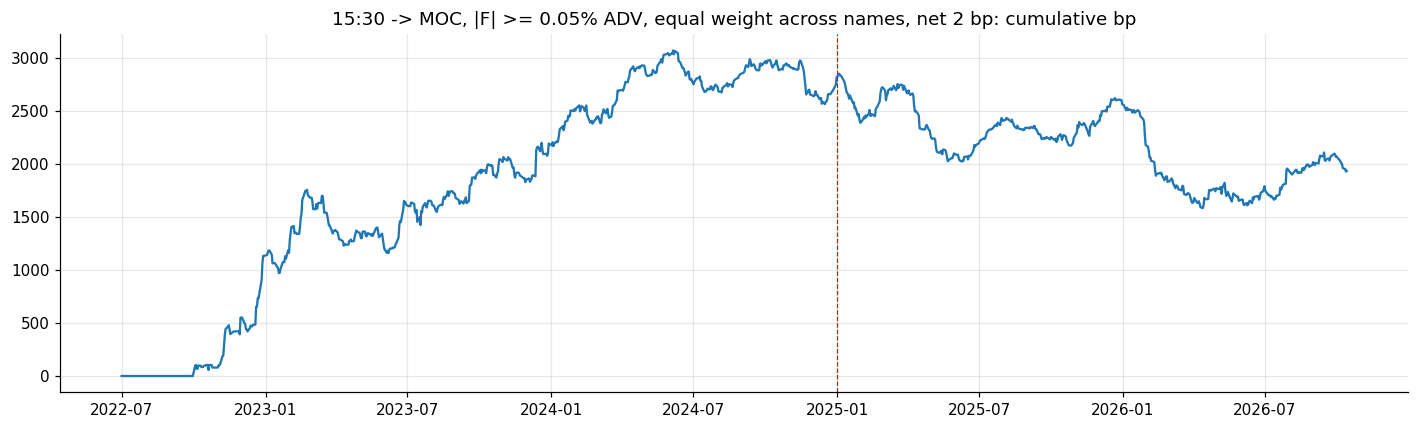


by year:
       mean  count     t
date                    
2022  31.02     39  3.14
2023   5.29    392  1.89
2024   3.26   1240  1.68
2025   1.67   4218  1.44
2026  -0.99   5100 -0.85

by stock:
        mean  count
sym                
TSLA    3.07    877
COIN    0.54    779
NVDA    0.89    716
MSTR    7.14    518
GOOGL  -0.48    471
SMCI    4.37    467
AMD    -1.92    462
PLTR   -0.05    443
TSM    -3.83    402
AMZN   -0.20    395
META    2.07    382
IONQ   -5.05    373
HOOD   -2.68    368
MU     -2.63    360
HIMS    0.79    355
RKLB    3.47    351
AVGO   -5.16    347
QBTS    2.66    334
RGTI   -0.69    328
QUBT    1.96    290
ASTS   -5.84    284
SMR     6.25    282
BMNR   10.67    252
CRCL   -3.51    249
MSFT   -1.78    245
IREN   18.26    227
AAPL   -7.92    164
NOW     3.37    134
AAOI   -0.65    134


In [13]:
ins = pd.DataFrame([stats_for(d[d["is"]], k, 2) for k in KS]).dropna()
K = ins.loc[ins.sharpe.idxmax(), "k"] if len(ins) else 0.5
print(f"chosen k = {K}% of ADV")
for c in [0, 1, 2, 5, 10]:
    a, b = stats_for(d[d["is"]], K, c), stats_for(d[~d["is"]], K, c)
    print(f"cost {c:2d} bp: IS {a.get('bp_per_trade', np.nan):+6.2f} bp/trade Sharpe {a.get('sharpe', np.nan):+5.2f} | "
          f"OOS {b.get('bp_per_trade', np.nan):+6.2f} bp/trade Sharpe {b.get('sharpe', np.nan):+5.2f} t {b.get('t', np.nan):+.1f}")
t = d[d.F.abs() >= K]
daily = (t.pnl - 2).groupby(t.date).mean().reindex(sorted(d.date.unique()), fill_value=0)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily.index, daily.cumsum()); ax.axvline(SPLIT, c="r", ls="--", lw=0.8)
ax.set_title(f"15:30 -> MOC, |F| >= {K}% ADV, equal weight across names, net 2 bp: cumulative bp"); plt.tight_layout(); plt.show()
print("\nby year:"); print(t.groupby(t.date.dt.year).pnl.agg(["mean", "count", lambda x: x.mean() / x.std() * np.sqrt(len(x))]).rename(columns={"<lambda_0>": "t"}).round(2).to_string())
print("\nby stock:"); print(t.groupby("sym").pnl.agg(["mean", "count"]).sort_values("count", ascending=False).round(2).to_string())

**Interpretation.**
- **The in-sample result is plain momentum, not LETF flow.** The in-sample Sharpe of 2.65 (gross, k = 0.05% ADV)
  comes from a threshold low enough to trade almost every stock-day with a move, so it is intraday momentum. §6 shows
  G adds nothing to it.
- **It decays and dies out-of-sample.** Out-of-sample it earns +0.2bp per trade (Sharpe 0.01). By year, the gain falls
  from +31bp (2022, 39 trades) to +5, +3, +1.7, and −1.0bp in 2026, just as LETF AUM grew. That is the opposite of
  what the thesis predicts.
- **After 2bp cost it loses out-of-sample** (Sharpe −1.05).

## 9. Robustness
**What this does.**
* **Volatility control.** High-G names are also high-volatility names. Add $r_{0\to15:30} \times \sigma$ (20-day vol) so
  that "volatile stocks trend into the close" cannot pass as an LETF effect.
* **Stock and month fixed effects** in the 15:30 → close regression: identification then comes only from G changing
  within a stock over time.
* **Leave one out.** Drop each stock in turn; the coefficient should not hinge on one name (TSLA, MSTR).
* **Placebo.** Same regression on the 14:30 → 15:00 window, where the rebalance should not yet be happening.

In [14]:
d = P.dropna(subset=["r30", "rs", "F", "spy30", "sig"]).copy()
d["rs_sig"] = d.rs * d.sig * 100
def reg(dd, cols, fe=False):
    X = dd[cols]
    if fe:
        X = pd.concat([X, pd.get_dummies(dd.sym, drop_first=True, dtype=float),
                       pd.get_dummies(dd.date.dt.to_period("M").astype(str), drop_first=True, dtype=float)], axis=1)
    f = sm.OLS(dd.r30, sm.add_constant(X)).fit(cov_type="cluster", cov_kwds={"groups": dd.date.factorize()[0]})
    return f.params.F, f.tvalues.F
rows = [("base", *reg(d, ["rs", "F", "spy30"])), ("+ rs x vol", *reg(d, ["rs", "rs_sig", "F", "spy30"])),
        ("+ stock & month FE", *reg(d, ["rs", "rs_sig", "F", "spy30"], fe=True))]
for sym in sorted(d.sym.unique()):
    rows.append((f"drop {sym}", *reg(d[d.sym != sym], ["rs", "rs_sig", "F", "spy30"])))
print(pd.DataFrame(rows, columns=["spec", "c(F) bp per 1% ADV", "t"]).round(2).to_string(index=False))

j0, j1 = list(BARS).index("14:25"), list(BARS).index("14:55")     # ends of the 14:25 and 14:55 bars: 14:30 -> 15:00
pl = pd.DataFrame({"y": (LLc[:, j1] - LLc[:, j0]) * 1e4, "rs": (np.exp(LLc[:, j0]) - 1) * 100,
                   "spy": (SPc[:, j1] - SPc[:, j0]) * 1e4, "date": P.date}).assign(F=lambda x: Gv * x.rs).dropna()
f = sm.OLS(pl.y, sm.add_constant(pl[["rs", "F", "spy"]])).fit(cov_type="cluster", cov_kwds={"groups": pl.date.factorize()[0]})
print(f"\nplacebo 14:30 -> 15:00: c(F) = {f.params.F:+.2f} bp per 1% ADV (t {f.tvalues.F:+.1f})")

              spec  c(F) bp per 1% ADV     t
              base               -0.97 -0.96
        + rs x vol               -0.91 -0.97
+ stock & month FE               -0.89 -0.99
         drop AAOI               -0.87 -0.91
         drop AAPL               -0.95 -1.01
          drop AMD               -0.96 -1.02
         drop AMZN               -0.94 -1.00
         drop ASTS               -0.63 -0.66
         drop AVGO               -0.93 -0.99
         drop BMNR               -0.73 -0.76
         drop COIN               -0.74 -0.72
         drop CRCL               -0.94 -1.00
        drop GOOGL               -0.93 -0.99
         drop HIMS               -0.87 -0.93
         drop HOOD               -0.88 -0.93
         drop IONQ               -0.90 -0.97
         drop IREN               -0.90 -0.96
         drop META               -0.93 -0.99
         drop MSFT               -0.92 -0.98
         drop MSTR               -0.66 -0.60
           drop MU               -1.22 -1.22
          

**Interpretation.**
- **The negative coefficient is consistent but not significant.** $c(F)$ ranges from −0.6 to −1.2 across all 33
  specs: volatility control, stock + month fixed effects, and dropping each stock in turn (t between −0.6 and −1.2).
  No single name drives the result, and nothing anywhere turns positive.
- **The placebo is clean.** In the 14:30 → 15:00 window, $c = -0.15$ (t = −0.2).

## 10. Takeaways

| question | answer |
|---|---|
| How big is the flow? | **Large.** $18.5bn AUM; 7 stocks where the forced trade is > 0.5× ADV per unit return; 1–3% of ADV on a median day in the top names. |
| Mechanism (closing volume) | **Not detectable** with 5-minute vendor volume (t = 0.8). Inconclusive, not negative. |
| Where does impact land? | **Not in the last 30 minutes** (no positive bucket). One positive blip at 15:05 (t = 4.6). |
| 15:30 → close continuation | **No.** c = −3.2bp per 1% ADV (t = −1.7). High-G names continue *less* than low-G names after the same move. |
| Overnight reversal | **Yes, weakly.** −11bp per 1% ADV (t = −3.4); −6bp (t = −2.3) after the volatility control. |
| Tradable? | **Front-run (the pitch): no.** OOS Sharpe 0.0 gross, −1.0 after 2bp. **Reversal (MOC → MOO): not stable.** IS loses, OOS +11bp/trade from one side and one year. |

**Verdict.** The trade as pitched (front-run the close from 15:30) is dead. The flow is large and predictable, but by
15:30 it is already in the price, or it is absorbed at the close without moving it. Plain intraday momentum, which
drove the in-sample Sharpe, has decayed to zero since 2022.

**Worth a follow-up, in this order:**
1. **The 15:05 blip.** Rerun on 1-minute bars around 15:00 and check issuer documents for hedge timing. If dealers
   hedge from 15:00, the window to front-run is 14:30–15:00, not 15:30–16:00.
2. **Better AUM.** Month-end N-PORT is stale by up to 3 months. Issuers post daily shares outstanding, so archiving
   them going forward would test whether the stale size hides the effect.
3. **The overnight reversal on the full cross-section** (all 141 underlyings, daily data only, no intraday needed).
   It is cheap to run and would tell whether the 2026 buy-side bounce is LETF flow or meme-stock beta.

**Caveats.** The 30-stock intraday sample was chosen by *today's* G, so it over-weights names that became LETF-heavy.
This is selection, not look-ahead in the signal. ETFs that closed and left Yahoo are missing, which understates
G in 2023–24. Bars are vendor composites, not consolidated tape. The overnight leg's return includes the open
auction; MOO orders fill there, so it is reachable, but spreads on small names at the open are wider than modelled.